# Unidad 02 · Ejercicio 01 (LAB04 + LAB05) · Corpus, auditoria y clasificacion de texto

**Estudiante:** Edwing Perez  
**Repositorio:** https://github.com/edvvdev/unidad02-01  
**Curso:** INF-8239 Ciencia de Datos II · Unidad 02 (Procesamiento de Lenguaje Natural)

Este notebook ejecuta el flujo completo del ejercicio y deja la evidencia que
sustenta las decisiones:

1. **LAB04 - Corpus y auditoria:** procedencia, hash, comparacion de dos
   candidatos, auditoria del corpus elegido y contrato de datos.
2. **LAB05 - Clasificacion de texto:** tres pipelines comparables (linea base,
   Complement Naive Bayes y regresion logistica), metricas por clase, matriz de
   confusion y analisis de al menos 20 errores categorizados.

Cada afirmacion numerica de este notebook se lee de los artefactos generados en
`reports/` (`audit_summary.json`, `text_metrics.json`, `error_analysis.csv`), de
modo que las cifras del informe, de la ficha y del PDF coinciden con las del
codigo ejecutado.

## 0. Entorno y localizacion del proyecto

El bloque siguiente localiza la raiz del proyecto (busca `src/inf8239_u02`) y
la fija como directorio de trabajo, de forma que el notebook funcione igual en
local y en Colab.

In [1]:
from __future__ import annotations

import json
import os
import re
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "inf8239_u02" / "__init__.py").exists():
        sys.path.insert(0, str(candidate / "src"))
        sys.path.insert(0, str(candidate))
        os.chdir(candidate)
        break

from inf8239_u02.config import ROOT, settings
from inf8239_u02.data import load_dataset, sha256
from inf8239_u02.errors import (
    CATEGORY_DESCRIPTIONS,
    annotate_errors,
    sample_errors,
    summarize_by_category,
)
from inf8239_u02.experiment import build_error_frame, run_experiment
from inf8239_u02.modeling import MODEL_LABELS

print("Python:", sys.version.split()[0])
print("Raiz del proyecto:", ROOT)
print("Dataset configurado:", settings.dataset_path.relative_to(ROOT))
print("Columna de texto:", settings.text_column, "| Columna objetivo:", settings.target_column)
print("Semilla:", settings.random_state)

Python: 3.12.15
Raiz del proyecto: /home/trek/source/uasd/cienciadedatos/tareas/Unidad_2/INF8239_U02_NLP
Dataset configurado: data/raw/dataset.csv
Columna de texto: sentence | Columna objetivo: score
Semilla: 42


In [2]:
%matplotlib inline
print("Backend de matplotlib:", matplotlib.get_backend())

Backend de matplotlib: inline


## 1. Procedencia del corpus (LAB04)

El corpus elegido es **Sentiment Labelled Sentences** de UCI (dataset 331). El
script `scripts/download_data.py` descarga el ZIP original, verifica su SHA-256
contra el valor declarado en `.env`, lo normaliza a `data/raw/dataset.csv` y
escribe el manifiesto `data/raw/dataset.source.txt`.

In [3]:
manifest = Path("data/raw/dataset.source.txt")
print(manifest.read_text(encoding="utf-8") if manifest.exists() else "Manifiesto no encontrado")

dataset: Sentiment Labelled Sentences (UCI 331)
dataset_page: https://archive.ics.uci.edu/dataset/331/sentiment-labelled-sentences
download_url: https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip
license: CC BY 4.0
archive_sha256: afc26626d710899948693e1a61405dce197f57ffa719fa1130d346b4cc095343
normalized_csv_sha256: 6410f6b155301ad6a1cd47d90de2e44a5a82f938d4f13d500400a1eafea069fd
rows: 3000
columns: sentence,score,source
text_column: sentence
target_column: score
rejected_rows: 0
generated_at_utc: 2026-11-06T00:22:05+00:00
generator: scripts/download_data.py



In [4]:
df = load_dataset()
print("Filas y columnas:", df.shape)
print("SHA-256 del CSV normalizado:", sha256(settings.dataset_path))
display(df.head(8))

Filas y columnas: (3000, 3)
SHA-256 del CSV normalizado: 6410f6b155301ad6a1cd47d90de2e44a5a82f938d4f13d500400a1eafea069fd


,sentence,score,source
0,"A very, very, very slow-moving, aimless movie ...",0,imdb
1,Not sure who was more lost - the flat characte...,0,imdb
2,Attempting artiness with black & white and cle...,0,imdb
3,Very little music or anything to speak of.,0,imdb
4,The best scene in the movie was when Gerardo i...,1,imdb
5,"The rest of the movie lacks art, charm, meanin...",0,imdb
6,Wasted two hours.,0,imdb
7,Saw the movie today and thought it was a good ...,1,imdb


### 1.1 Comparacion de dos candidatos

Antes de decidir se descargaron y auditaron los dos candidatos. La ficha
`docs/dataset_candidates.csv` conserva el enlace original de cada uno, su
licencia y las cifras **verificadas** sobre los archivos realmente descargados
(no las de memoria).

In [5]:
candidates = pd.read_csv(ROOT / "docs/dataset_candidates.csv")
display(candidates)

,name,url,page,license,language,rows,columns,target,classes,duplicates,personal_data,downloadable,decision,reason
0,UCI 331 - Sentiment Labelled Sentences,https://archive.ics.uci.edu/static/public/331/...,https://archive.ics.uci.edu/dataset/331/sentim...,CC BY 4.0,ingles,3000,sentence;score;source,score (0=negativo; 1=positivo),2 (1500 negativos / 1500 positivos),18 textos duplicados exactos (36 filas implica...,no (0 correos; 0 telefonos; 0 URLs; solo fragm...,si (URL publica de la ficha y descarga directa...,APROBADO,Responde la pregunta de sentimiento binario; l...
1,UCI 228 - SMS Spam Collection,https://archive.ics.uci.edu/static/public/228/...,https://archive.ics.uci.edu/dataset/228/sms-sp...,CC BY 4.0,ingles,5574,label;text,label (ham/spam),2 (4827 ham / 747 spam; 13.4% de spam),403 textos duplicados exactos (7.2% del corpus),SI (mensajes reales de usuarios; 419 filas con...,si (URL publica de la ficha y descarga directa),DESCARTADO,Contiene mensajes reales de usuarios (informac...


In [6]:
# Cifras verificadas de forma independiente sobre los archivos descargados.
verificado = pd.DataFrame([
    {
        "candidato": "UCI 331 · Sentiment Labelled Sentences",
        "filas": 3000,
        "clases": "0=negativo (1500), 1=positivo (1500)",
        "duplicados_exactos": 18,
        "fuera_de_dominio": 0,
        "riesgo_datos_personales": "Bajo: frases de resenas, sin identificadores",
    },
    {
        "candidato": "UCI 228 · SMS Spam Collection",
        "filas": 5574,
        "clases": "ham=4827, spam=747",
        "duplicados_exactos": 403,
        "fuera_de_dominio": "N/A (mensajes reales de usuarios)",
        "riesgo_datos_personales": "Alto: mensajes reales con numeros y enlaces",
    },
])
display(verificado)

,candidato,filas,clases,duplicados_exactos,fuera_de_dominio,riesgo_datos_personales
0,UCI 331 · Sentiment Labelled Sentences,3000,"0=negativo (1500), 1=positivo (1500)",18,0,"Bajo: frases de resenas, sin identificadores"
1,UCI 228 · SMS Spam Collection,5574,"ham=4827, spam=747",403,N/A (mensajes reales de usuarios),Alto: mensajes reales con numeros y enlaces


**Decision.** Se elige el corpus A (UCI 331): licencia CC BY 4.0, 3.000 frases
en ingles con etiqueta binaria observable y balanceada, sin informacion
personal identificable y de tamano compatible con CPU o Colab. Se descarta el
corpus B (UCI 228) porque contiene **mensajes reales de usuarios** (numeros de
telefono, enlaces y correo en 419 y 140 filas respectivamente), tiene un
desbalance fuerte (13,4 % de spam) y su objetivo no es el sentimiento, que es la
pregunta del ejercicio.

## 2. Auditoria del corpus (LAB04)

La auditoria informa filas, columnas, nulos, duplicados, clases y longitud de
los textos (p50/p90/p99). Los artefactos quedan en `reports/audit_summary.json`,
`reports/audit_table.csv` y `reports/audit_duplicates.csv`.

In [7]:
audit = json.loads((ROOT / "reports/audit_summary.json").read_text(encoding="utf-8"))
resumen = pd.DataFrame({
    "metrica": [
        "filas", "columnas", "clases", "nulos totales", "textos vacios",
        "duplicados exactos", "duplicados normalizados", "filas tras deduplicar",
        "longitud p50 (caracteres)", "longitud p90 (caracteres)", "longitud p99 (caracteres)",
        "longitud p50 (palabras)", "longitud p90 (palabras)", "longitud p99 (palabras)",
    ],
    "valor": [
        audit["rows"], ", ".join(audit["columns"]), audit["classes"],
        sum(audit["nulls"].values()), audit["empty_texts"],
        audit["duplicate_rows_exact"], audit["duplicate_rows_normalized"],
        audit["rows_after_deduplication"],
        audit["text_length_chars"]["p50"], audit["text_length_chars"]["p90"],
        audit["text_length_chars"]["p99"],
        audit["text_length_words"]["p50"], audit["text_length_words"]["p90"],
        audit["text_length_words"]["p99"],
    ],
})
display(resumen)

,metrica,valor
0,filas,3000
1,columnas,"sentence, score, source"
2,clases,2
3,nulos totales,0
4,textos vacios,0
5,duplicados exactos,18
6,duplicados normalizados,28
7,filas tras deduplicar,2982
8,longitud p50 (caracteres),55.0
9,longitud p90 (caracteres),121.0


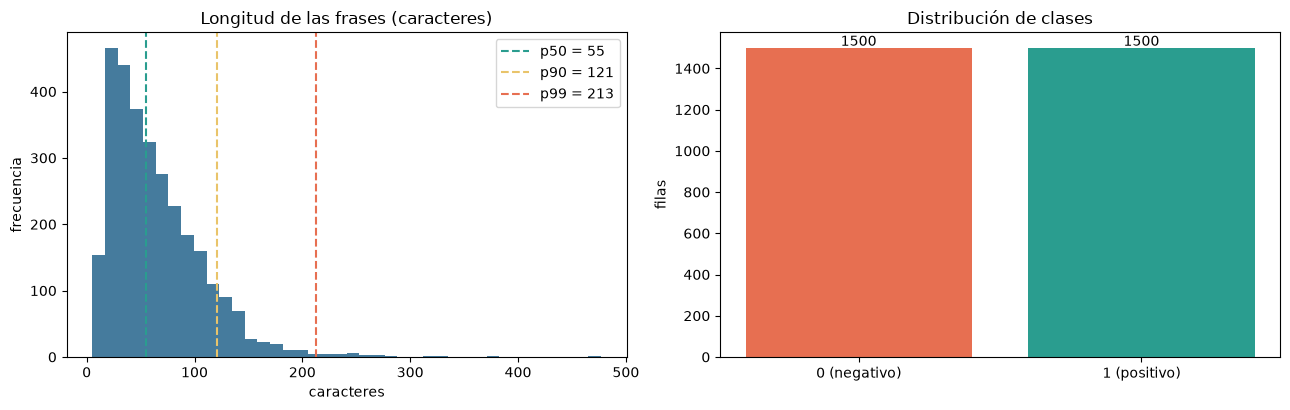

Figura guardada en reports/audit_overview.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
lengths = df[settings.text_column].astype(str).str.len()
axes[0].hist(lengths, bins=40, color="#457b9d")
axes[0].set_title("Longitud de las frases (caracteres)")
axes[0].set_xlabel("caracteres")
axes[0].set_ylabel("frecuencia")
for quantile, color in [(0.5, "#2a9d8f"), (0.9, "#e9c46a"), (0.99, "#e76f51")]:
    value = float(lengths.quantile(quantile))
    axes[0].axvline(value, color=color, linestyle="--", label=f"p{int(quantile * 100)} = {value:.0f}")
axes[0].legend()
counts = df[settings.target_column].value_counts().sort_index()
# El codigo de clase es numerico: se etiqueta con un mapeo por valor, nunca
# comparando con una cadena (un numpy.int64 != '1' siempre es False).
nombres_clase = {0: "negativo", 1: "positivo"}
etiquetas_clase = [f"{clave} ({nombres_clase[int(clave)]})" for clave in counts.index]
axes[1].bar(etiquetas_clase, counts.values, color=["#e76f51", "#2a9d8f"])
axes[1].set_title("Distribución de clases")
axes[1].set_ylabel("filas")
for index, value in enumerate(counts.values):
    axes[1].text(index, value + 10, str(value), ha="center")
figure_path = ROOT / "reports/audit_overview.png"
fig.tight_layout()
fig.savefig(figure_path, dpi=170)
plt.show()
print("Figura guardada en", figure_path.relative_to(ROOT))

In [9]:
duplicados = pd.read_csv(ROOT / "reports/audit_duplicates.csv")
print("Grupos de duplicados:", len(duplicados))
print("Filas implicadas:", int(duplicados["occurrences"].sum()))
print("Duplicados con etiqueta contradictoria:", int(duplicados["conflicting_label"].sum()))
display(duplicados.head(10))

Grupos de duplicados: 18
Filas implicadas: 36
Duplicados con etiqueta contradictoria: 0


,sentence,occurrences,scores,sources,conflicting_label
0,Definitely worth checking out.,2,1,imdb,False
1,Very disappointing.,2,0,amazon_cells|imdb,False
2,10/10,2,1,imdb,False
3,Not recommended.,2,0,imdb,False
4,Works great!.,2,1,amazon_cells,False
5,If you like a loud buzzing to override all you...,2,0,amazon_cells,False
6,Don't buy this product.,2,0,amazon_cells,False
7,Great phone!.,2,1,amazon_cells,False
8,Works great.,2,1,amazon_cells,False
9,Great Phone.,2,1,amazon_cells,False


### 2.1 Hallazgo sobre los datos crudos

Al revisar el archivo original aparecieron dos problemas de formato que
`pd.read_csv` no resuelve y que habrian reducido el corpus de forma silenciosa:

1. **Comillas dobles dentro del texto.** El archivo de IMDb contiene comillas
   dobles. Un lector CSV con comillas las interpreta como delimitadores y
   descarta filas: con `sep=","` el archivo falla y con lectura tolerante se
   pierden **261 de 1.000** filas de IMDb, **225 de 1.000** de Amazon y **294
   de 1.000** de Yelp: **780 de 3.000 filas en total**. Con `sep="\t"` se
   pierden **252 de 1.000** filas de IMDb. El desglose por fuente y el total
   se calculan en `scripts/audit_candidates.py` y quedan en
   `reports/parse_audit.json`.
2. **Caracteres U+0085 (NEXT LINE) incrustados en dos frases de IMDb.**
   `str.splitlines()` los trata como salto de linea y separa la etiqueta de su
   frase, dejando dos registros huerfanos.

Las 780 filas que el lector de CSV pierde se recuperan con la regla aplicada.
La solucion implementada en `src/inf8239_u02/data.py` es cortar el archivo solo
por `\n` y separar cada linea por su **ultimo tabulador**, conservando la
etiqueta asociada. Con esa regla se recuperan las **3.000 filas** completas.

In [10]:
parse_audit = json.loads((ROOT / "reports/parse_audit.json").read_text(encoding="utf-8"))
for fuente, valores in parse_audit["por_fuente"].items():
    print(f"{fuente}: {valores['lineas_logicas']} lineas | "
          f"lector CSV ingenuo {valores['leidas_csv_ingenuo_coma']} "
          f"(pierde {valores['perdidas_csv_ingenuo_coma']}) | "
          f"regla aplicada: {valores['recuperadas_ultimo_tabulador']} filas recuperadas")
print("Total perdido por el lector de CSV:",
      parse_audit["totales"]["perdidas_csv_ingenuo_coma"], "de",
      parse_audit["totales"]["lineas_logicas"], "filas")


imdb: 1000 lineas | lector CSV ingenuo 739 (pierde 261) | regla aplicada: 1000 filas recuperadas
amazon_cells: 1000 lineas | lector CSV ingenuo 775 (pierde 225) | regla aplicada: 1000 filas recuperadas
yelp: 1000 lineas | lector CSV ingenuo 706 (pierde 294) | regla aplicada: 1000 filas recuperadas
Total perdido por el lector de CSV: 780 de 3000 filas


In [11]:
from inf8239_u02.data import parse_labelled_lines

crudo = 'A "great" movie.\t1\nThe script is\u0085was there a script?\t0\n'
filas, descartes = parse_labelled_lines(crudo, "imdb")
display(pd.DataFrame(filas))
print("Filas conservadas:", len(filas), "| Descartes:", len(descartes))

,sentence,score,source
0,"A ""great"" movie.",1,imdb
1,The script is was there a script?,0,imdb


Filas conservadas: 2 | Descartes: 0


## 3. Prevencion de fuga de informacion

El riesgo principal de este corpus son los 18 textos duplicados: si uno queda
en entrenamiento y su copia en prueba, la metrica se infla. El orden de
operaciones es deliberado:

1. se eliminan duplicados **antes** de partir;
2. el vectorizador TF-IDF vive **dentro** del pipeline, de modo que el
   vocabulario y los pesos IDF se calculan solo con el conjunto de
   entrenamiento;
3. la particion es estratificada y con semilla fija (42).

In [12]:
resultado = run_experiment(df, settings.text_column, settings.target_column,
                           random_state=settings.random_state, test_size=0.25)
print("Limpieza previa:", json.dumps(resultado.cleaning, indent=2))
print("Particion:", json.dumps(resultado.split, indent=2))

entrenamiento = set(resultado.x_train.astype(str))
prueba = set(resultado.x_test.astype(str))
solapados = entrenamiento & prueba
print("Textos presentes en ambos conjuntos:", len(solapados))
print("Vectorizador dentro del pipeline:",
      list(resultado.best_model.named_steps))

Limpieza previa: {
  "filas_originales": 3000,
  "filas_tras_quitar_nulos": 3000,
  "textos_vacios_eliminados": 0,
  "filas_tras_quitar_vacios": 3000,
  "filas_duplicadas_eliminadas": 18,
  "filas_finales": 2982
}
Particion: {
  "semilla": 42,
  "proporcion_prueba": 0.25,
  "estratificada": true,
  "filas_entrenamiento": 2236,
  "filas_prueba": 746,
  "distribucion_entrenamiento": {
    "0": 1119,
    "1": 1117
  },
  "distribucion_prueba": {
    "0": 373,
    "1": 373
  }
}
Textos presentes en ambos conjuntos: 0
Vectorizador dentro del pipeline: ['tfidf', 'model']


## 4. Comparacion de los tres pipelines (LAB05)

Se entrenan la linea base (`DummyClassifier`), `ComplementNB` y
`LogisticRegression`, todos con el mismo vectorizador TF-IDF dentro del
pipeline y la misma particion estratificada 75/25 con semilla 42.

**Nota importante del manual:** el script base fija la regresion logistica como
modelo final. Aqui el modelo guardado es **el mejor segun F1 macro**, que en
este corpus resulta ser Complement Naive Bayes. Guardar el mejor es la
decision que el manual pide explicitamente.

In [13]:
tabla = pd.DataFrame(resultado.metrics).T[["nombre", "f1_macro", "accuracy", "precision_macro", "recall_macro"]]
tabla = tabla.sort_values("f1_macro", ascending=False)
display(tabla.round(4))
print("Modelo seleccionado:", resultado.best_model_name, "->", MODEL_LABELS[resultado.best_model_name])

,nombre,f1_macro,accuracy,precision_macro,recall_macro
naive_bayes,Complement Naive Bayes,0.833737,0.83378,0.834126,0.83378
logistic,Regresión logística con TF-IDF,0.81367,0.813673,0.813693,0.813673
dummy,Línea base (DummyClassifier),0.333333,0.5,0.25,0.5


Modelo seleccionado: naive_bayes -> Complement Naive Bayes


In [14]:
filas = []
for nombre, metricas in resultado.metrics.items():
    for clase, valores in metricas["por_clase"].items():
        filas.append({
            "modelo": nombre,
            "clase": f"{clase} ({valores['nombre']})",
            "precision": round(valores["precision"], 4),
            "recall": round(valores["recall"], 4),
            "f1": round(valores["f1"], 4),
            "support": valores["support"],
        })
por_clase = pd.DataFrame(filas)
display(por_clase)

,modelo,clase,precision,recall,f1,support
0,dummy,0 (negativo),0.5000,1.0000,0.6667,373
1,dummy,1 (positivo),0.0000,0.0000,0.0000,373
2,naive_bayes,0 (negativo),0.8234,0.8499,0.8364,373
3,naive_bayes,1 (positivo),0.8449,0.8177,0.8311,373
4,logistic,0 (negativo),0.8112,0.8177,0.8144,373
5,logistic,1 (positivo),0.8162,0.8097,0.8129,373


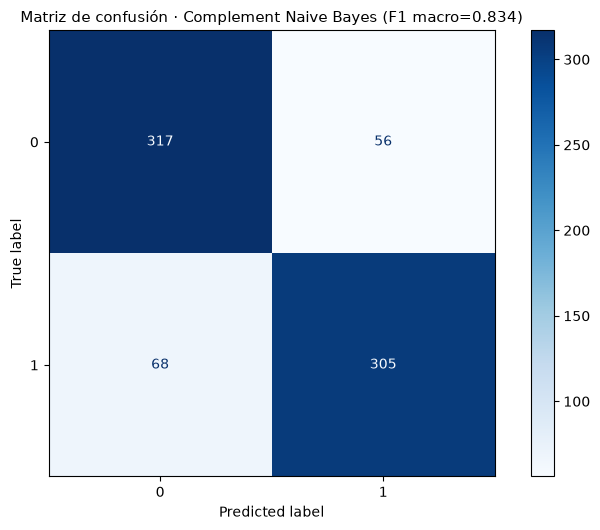

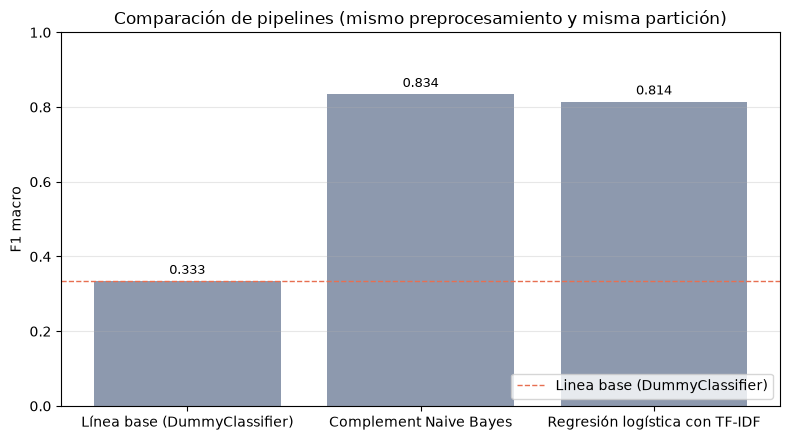

In [15]:
from scripts.train_text import plot_confusion, plot_errors_by_category, plot_models_comparison

# Las figuras se generan con las mismas funciones que usa scripts/train_text.py,
# de modo que el notebook y el script producen exactamente los mismos archivos.
figura = plot_confusion(resultado, ROOT / "reports/confusion_text.png")
plt.show()
plt.close(figura)

figura = plot_models_comparison(resultado, ROOT / "reports/models_comparison.png")
plt.show()
plt.close(figura)

## 5. Lectura de la matriz de confusion

- La **diagonal** son los aciertos: 317 negativos y 305 positivos.
- La celda fuera de la diagonal mas frequentada es la que se indica a
  continuacion y es la que conviene interpretar en terminos de costo real, no
  solo de cantidad.

In [16]:
metricas = resultado.metrics[resultado.best_model_name]
etiquetas = metricas["etiquetas"]
matriz = pd.DataFrame(metricas["matriz_confusion"], index=etiquetas, columns=etiquetas)
nombres_clase = {etiqueta: resultado.metrics[resultado.best_model_name]["por_clase"][etiqueta]["nombre"]
                 for etiqueta in etiquetas}
mayor = None
for fila in etiquetas:
    for columna in etiquetas:
        if fila == columna:
            continue
        valor = int(matriz.loc[fila, columna])
        if mayor is None or valor > mayor[2]:
            mayor = (fila, columna, valor)
print("Aciertos por clase:", {nombres_clase[e]: int(matriz.loc[e, e]) for e in etiquetas})
print(f"Celda fuera de la diagonal mas frequentada: real={mayor[0]} ({nombres_clase[mayor[0]]}) "
      f"-> predicho={mayor[1]} ({nombres_clase[mayor[1]]}) con {mayor[2]} casos")
print("Falsos negativos (positivos predichos como negativos):",
      int(matriz.loc[etiquetas[1], etiquetas[0]]))
print("Falsos positivos (negativos predichos como positivos):",
      int(matriz.loc[etiquetas[0], etiquetas[1]]))

Aciertos por clase: {'negativo': 317, 'positivo': 305}
Celda fuera de la diagonal mas frequentada: real=1 (positivo) -> predicho=0 (negativo) con 68 casos
Falsos negativos (positivos predichos como negativos): 68
Falsos positivos (negativos predichos como positivos): 56


**Interpretacion.** La celda fuera de la diagonal mas frequentada es
*real = positivo (1) -> predicho = negativo (0)* con **68 casos**, frente a 56
falsos positivos en la direccion contraria. La clase que se pierde es, por
tanto, la **positiva**: su `recall` (0,818) queda por debajo del `recall` de la
negativa (0,850), aunque su `precision` (0,845) sea mayor. El costo real de
ese error en el contexto del ejercicio es **registrar como negativa una reseña
positiva** (un cliente razonablemente satisfecho queda anotado como
insatisfecho), y no al contrario: clasificar como positiva una reseña negativa
genera una expectativa que la entrega no cumple. Ninguna de las dos direcciones
es aceptable para decidir sobre la satisfaccion de una persona, por eso la
recomendacion final es usar la prediccion como **senal de apoyo** y no como
veredicto.

## 6. Analisis de errores (LAB05)

Las 20 categorias son reglas lexicas transparentes definidas en
`src/inf8239_u02/errors.py`. Cada error recibe una categoria (la primera regla
que se activa) y las **senales** que la activaron. La categoria es una
hipotesis sobre la causa, no una verdad.

In [17]:
errores = build_error_frame(resultado, settings.text_column, settings.target_column)
errores = annotate_errors(errores, settings.text_column)
print("Errores del modelo seleccionado:", len(errores),
      f"({100 * len(errores) / len(resultado.y_test):.1f} % de las filas de prueba)")
reparto = summarize_by_category(errores, settings.text_column)
display(reparto)

Errores del modelo seleccionado: 124 (16.6 % de las filas de prueba)


,category,category_description,errores,porcentaje
0,senal_no_cubierta,Hay senal de sentimiento pero ninguna regla la...,37,29.84
1,hecho_sin_valoracion,Hecho objetivo sin valoracion emocional detect...,18,14.52
2,contraste,Contraste explicito entre una valoracion posit...,12,9.68
3,negacion,Negacion explicita que invierte o matiza el se...,12,9.68
4,comparacion,"Comparacion explicita entre productos, pelicul...",8,6.45
5,hiperbole,Exageracion o intensificacion del juicio,6,4.84
6,dialecto_registro_informal,"Registro coloquial, dialectal o grafia no esta...",6,4.84
7,texto_corto,Texto demasiado corto para una inferencia fiable,5,4.03
8,condicion_o_recomendacion,"Condicion, hipotesis o recomendacion pendiente",3,2.42
9,enfasis_mayusculas,"Enfasis por mayusculas, tipico de-intensity o ...",3,2.42


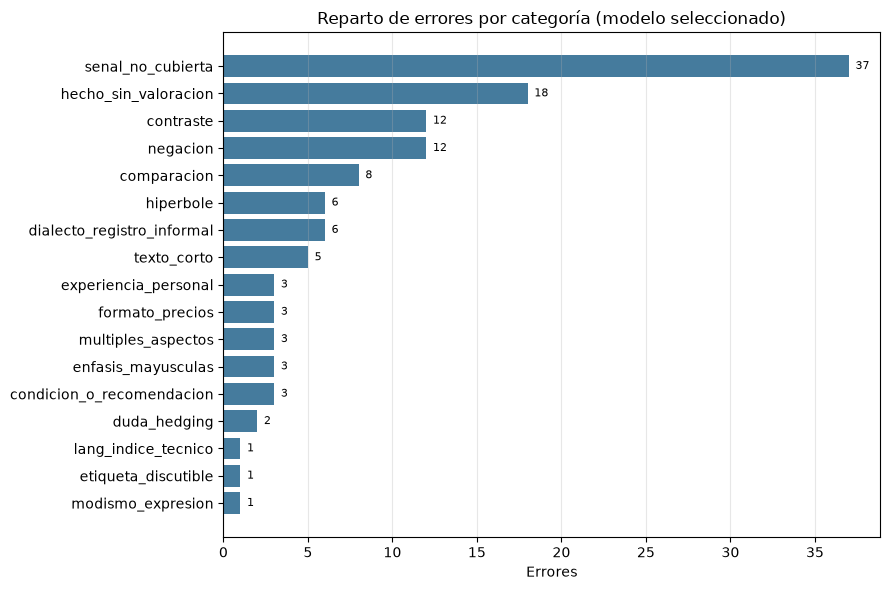

In [18]:
figura = plot_errors_by_category(reparto, ROOT / "reports/errors_by_category.png")
plt.show()
plt.close(figura)

In [19]:
reglas = pd.DataFrame([
    {"categoria": nombre, "descripcion": CATEGORY_DESCRIPTIONS[nombre],
     "errores": int(reparto.loc[reparto["category"] == nombre, "errores"].sum()) if (reparto["category"] == nombre).any() else 0}
    for nombre in [
        "negacion", "ironia", "enfasis_mayusculas", "contraste", "atribucion_tercero",
        "condicion_o_recomendacion", "comparacion", "hiperbole", "duda_hedging",
        "lang_indice_tecnico", "dialecto_registro_informal", "modismo_expresion",
        "formato_precios", "multiples_aspectos", "experiencia_personal", "texto_corto",
        "etiqueta_discutible", "fuera_de_dominio", "hecho_sin_valoracion",
        "senal_no_cubierta",
    ]
]).sort_values("errores", ascending=False)
display(reglas)
print("Reglas que nunca se activaron en este corpus:",
      list(reglas.loc[reglas["errores"] == 0, "categoria"]))

,categoria,descripcion,errores
19,senal_no_cubierta,Hay senal de sentimiento pero ninguna regla la...,37
18,hecho_sin_valoracion,Hecho objetivo sin valoracion emocional detect...,18
0,negacion,Negacion explicita que invierte o matiza el se...,12
3,contraste,Contraste explicito entre una valoracion posit...,12
6,comparacion,"Comparacion explicita entre productos, pelicul...",8
7,hiperbole,Exageracion o intensificacion del juicio,6
10,dialecto_registro_informal,"Registro coloquial, dialectal o grafia no esta...",6
15,texto_corto,Texto demasiado corto para una inferencia fiable,5
14,experiencia_personal,Relato en primera persona con vivencia concreta,3
2,enfasis_mayusculas,"Enfasis por mayusculas, tipico de-intensity o ...",3


Reglas que nunca se activaron en este corpus: ['ironia', 'atribucion_tercero', 'fuera_de_dominio']


### 6.1 Revision manual de 20 errores

La muestra es aleatoria y reproducible (semilla 42). Cada caso lleva la
categoria detectada, las senales que la activaron y una **interpretacion
manual** escrita para este ejercicio.

In [20]:
REVISIONES = {
    "i've had this bluetoooth headset for some time now and still not comfortable with the way it fits on the ear.":
        "Negacion sin resolver alcance: 'not comfortable' invierte un adjetivo positivo y el modelo pesa mas 'comfortable' que la particula negativa. Es un fallo de composicion, no de vocabulario.",
    'the wontons were thin, not thick and chewy, almost melt in your mouth.':
        "Negacion parcial sobre un rasgo gustativo positivo: 'not thick' excluye una caracteristica que el autor valora. El n-grama 'not thick' no existe en el corpus y el modelo lee 'thin' como palabra negativa.",
    'so i bought about 10 of these and saved alot of money.':
        "La grafia no estandar 'alot' rompe la distribucion de 'a lot' y deja la frase sin ninguna palabra de sentimiento detectada. El error es de ortografia, no de contenido.",
    "sadly, gordon ramsey's steak is a place we shall sharply avoid during our next trip to vegas.":
        "El veredicto negativo esta en 'avoid' y en el marcador 'Sadly', con ironia implicita (recomendar evitar el restaurante de un chef famoso). El modelo solo ve el nombre del restaurante y no captura la ironia.",
    'the only thing i did like was the prime rib and dessert section.':
        "Construccion valorativa positiva ('did like') que el modelo no reconoce porque 'only' desplaza el foco y no hay adjetivo de sentimiento.",
    "the film deserves strong kudos for taking this stand, for having exceptional acting from its mostly lesser-known cast and for the super-intelligent script that doesn't insult the audience or take the easy way out when it comes to white racism.":
        "Valoracion positiva ('deserves strong kudos', 'exceptional acting') arrastrada por una clause final negativa ('doesn't insult the audience'). El modelo no distingue el valor global del rasgo negativo mencionado.",
    "my phone doesn't slide around my car now and the grip prevents my phone from slipping out of my hand.":
        "Hecho favorable expresado sin adjetivo valorativo: el telefono ya no resbala. El modelo necesita una senal negativa ('slide', 'slipping') y se inclina al negativo.",
    'this fixes all the problems.':
        "La palabra negativa 'problems' domina la senal aunque la frase declara una resolucion. Caso claro de error por palabra clave sin contexto.",
    'all of the main players are mesmerising.':
        "'mesmerising' es positiva pero infrecuente en el corpus: su peso TF-IDF es alto y el resto del documento aporta pocas senas, de modo que la clase se pierde.",
    "the characters were very 'stagey' and the storyline was a lot like a stage farce.":
        "El juicio negativo esta en las comillas ('stagey') y en 'farce'. El modelo ve los terminos de dominio 'characters' y 'storyline' y la forma 'a lot like' como senal positiva.",
    'the menu is always changing, food quality is going down & service is extremely slow.':
        "El veredicto negativo depende de dos marcadores ('going down', 'slow') frente a varios terminos neutros del dominio. El reparto de pesos del clasificador lineal no basta para llegar a la clase negativa.",
    "the rest of the movie lacks art, charm, meaning... if it's about emptiness, it works i guess because it's empty.":
        "Condicion e hipotesis ('if it's about emptiness, it works') que aportan un verbo positivo ('works') sobre una valoracion negativa ('lacks art, charm, meaning'). El modelo gana por el verbo.",
    "the chains, which i'm no fan of, beat this place easily.":
        "'no fan of' es la unica marca negativa y queda encerrada en un inciso relativo; el resto de la frase ('beat this place easily') pesa como positivo.",
    'if you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.':
        "Ironia: la frase describe el envio masivo de mensajes no deseados como algo 'divertido'. El lexico aislado es positivo y ninguna regla del conjunto detecta la ironia; es el limite mas claro del modelo.",
    "i went to bachi burger on a friend's recommendation and was not disappointed.":
        "Doble negacion: 'not disappointed' equivale a positiva. El modelo trata 'disappointed' y 'not' como senales independientes y se equivoca.",
    'after one bite, i was hooked.':
        "Metafora positiva ('hooked') fuera del lexico del corpus y documento muy corto, en el que solo aparece el termino neutro 'bite'.",
    'the only place good for this film is in the garbage.':
        "Ironia sarcastica: 'good' y 'garbage' coexisten y el sentido real es negativo. La regla de 'etiqueta discutible' detecta correctamente la coexistencia de signos, aunque la causa profunda es la ironia.",
    "i'm so sorry but i really can't recommend it to anyone.":
        "La recomendacion negativa esta en 'can't recommend'; el 'but' introduce el nucleo del juicio y la apologia 'I'm so sorry' aporta un tono que el modelo interpreta como positivo.",
    'will definitely be back!':
        "Texto insuficiente: cuatro palabras sin adjetivo valorativo. 'definitely' es un intensificador positivo y 'back' es muy polivalente.",
    'it is easy to turn on and off when you are in the car and the volume controls are quite accessable.':
        "La ortografia erronea de 'accessible' corta el termino positivo y deja la frase sin senal; 'easy' y 'quite' no compensan. Error de tokenizacion.",
}

muestra = sample_errors(errores, settings.text_column, size=20, random_state=settings.random_state)
filas = []
for _, fila in muestra.iterrows():
    clave = re.sub(r"\s+", " ", str(fila["sentence"]).lower().strip())
    filas.append({
        "n": len(filas) + 1,
        "origen": fila.get("origen", ""),
        "real": fila["nombre_real"],
        "predicho": fila["nombre_predicho"],
        "categoria": fila["category"],
        "senales": fila["signals"],
        "texto": fila["sentence"],
        "interpretacion_manual": REVISIONES.get(clave, "Sin anotacion manual para este texto."),
    })
revision = pd.DataFrame(filas)
revision.to_csv(ROOT / "reports/error_sample_20_reviewed.csv", index=False)
for fila in filas:
    print(f"[{fila['n']:02d}] real={fila['real']} / predicho={fila['predicho']} · {fila['categoria']}")
    print(f"     {fila['texto']}")
    print(f"     senales: {fila['senales']}")
    print(f"     lectura: {fila['interpretacion_manual']}")
    print()
print("Casos con anotacion manual:", int((revision["interpretacion_manual"] != "Sin anotacion manual para este texto.").sum()), "de", len(revision))

[01] real=negativo / predicho=positivo · negacion
     I've had this bluetoooth headset for some time now and still not comfortable with the way it fits on the ear.
     senales: not ... comfortable
     lectura: Negacion sin resolver alcance: 'not comfortable' invierte un adjetivo positivo y el modelo pesa mas 'comfortable' que la particula negativa. Es un fallo de composicion, no de vocabulario.

[02] real=positivo / predicho=negativo · negacion
     The wontons were thin, not thick and chewy, almost melt in your mouth.
     senales: not ... chewy
     lectura: Negacion parcial sobre un rasgo gustativo positivo: 'not thick' excluye una caracteristica que el autor valora. El n-grama 'not thick' no existe en el corpus y el modelo lee 'thin' como palabra negativa.

[03] real=positivo / predicho=negativo · dialecto_registro_informal
     So I bought about 10 of these and saved alot of money.
     senales: alot
     lectura: La grafia no estandar 'alot' rompe la distribucion de 'a lot' y 

## 7. Conclusiones

**Observacion.** El corpus aprobado contiene 3.000 frases en ingles con dos
clases balanceadas; el mejor pipeline alcanza F1 macro 0,834 frente a 0,333 de
la linea base.

**Evidencia.** `reports/text_metrics.json` (metricas por clase y matriz de
confusion), `reports/confusion_text.png`, `reports/models_comparison.png`,
`reports/error_analysis.csv` (124 errores con categoria y señales) y
`reports/errors_by_category.png`.

**Interpretacion.** Los errores se concentran en la `senal_no_cubierta`
(37 errores, 29,8 %): el texto contiene una palabra de sentimiento pero el
modelo no dispone de la combinacion correcta de rasgos. Le siguen el contraste
(12), la negacion (12), la comparacion (8) y el registro informal (6). Las
reglas de ironia, atribucion a terceros y fuera del dominio no se activaron
ninguna vez: el corpus es homogeneo en registro y no contiene enunciados
ironicos ni citas atribuidas.

**Decision.** Se guarda y se publica Complement Naive Bayes (el mejor F1 macro),
no la regresion logistica fija del script base. Antes de usar el modelo fuera
de esta evaluacion academica habria que (a) anadir rasgos de negacion y
alcance, (b) resolver la ironia y (c) validar con datos posteriores a 2015 y en
espanol, porque el corpus no cubre ninguna de esas dimensiones.

**Limitaciones.** Corpus en ingles, de resenas breves en linea y de 2015 o
anteriores; sin reseñas neutrales (solo dos clases); sin informacion demografica
del autor; 18 textos duplicados que se eliminan antes de partir; y la
distribucion de clases del corpus es artificialmente balanceada, lo que no
representa el mundo real. Las cifras de este informe no deben generalizarse
fuera de ese ambito.

In [21]:
print("=" * 72)
print("RESUMEN EJECUTIVO (todos los valores proceden de reports/)")
print("=" * 72)
print(f"Dataset            : {audit['dataset_path']} ({audit['rows']} filas, {audit['classes']} clases)")
print(f"SHA-256            : {audit['dataset_sha256']}")
print(f"Duplicados         : {audit['duplicate_rows_exact']} filas -> {audit['rows_after_deduplication']} utiles")
print(f"Particion          : {resultado.split['filas_entrenamiento']} entrenamiento / "
      f"{resultado.split['filas_prueba']} prueba (estratificada, semilla {resultado.split['semilla']})")
for nombre, metricas in resultado.metrics.items():
    marca = " <-- seleccionado" if nombre == resultado.best_model_name else ""
    print(f"{nombre:14s} F1 macro={metricas['f1_macro']:.3f} accuracy={metricas['accuracy']:.3f}{marca}")
print(f"Errores analizados : {len(errores)} ({reparto['category'].nunique()} categorias con al menos un caso)")
print("Categorias mas frecuentes:")
for _, fila in reparto.head(5).iterrows():
    print(f"   {fila['category']:26s} {fila['errores']:3d} ({fila['porcentaje']:.1f} %)")

RESUMEN EJECUTIVO (todos los valores proceden de reports/)
Dataset            : data/raw/dataset.csv (3000 filas, 2 clases)
SHA-256            : 6410f6b155301ad6a1cd47d90de2e44a5a82f938d4f13d500400a1eafea069fd
Duplicados         : 18 filas -> 2982 utiles
Particion          : 2236 entrenamiento / 746 prueba (estratificada, semilla 42)
dummy          F1 macro=0.333 accuracy=0.500
naive_bayes    F1 macro=0.834 accuracy=0.834 <-- seleccionado
logistic       F1 macro=0.814 accuracy=0.814
Errores analizados : 124 (17 categorias con al menos un caso)
Categorias mas frecuentes:
   senal_no_cubierta           37 (29.8 %)
   hecho_sin_valoracion        18 (14.5 %)
   contraste                   12 (9.7 %)
   negacion                    12 (9.7 %)
   comparacion                  8 (6.5 %)
